# Sentiment distribution interactions and time coverage

Yuwei’s EDA, adapted from the combined feature exploration notebook. Outputs go to generated/eda_sentiment. The published original PNG figures remain in reports/eda/figures. Boxplot whiskers are explicitly set to the observed range to match the figure caption.

## 7 Exploratory data analysis
The next three code cells create the sentiment distribution, engagement comparison, and annual trend charts. Each cell reads the cleaned CSV directly from the project data folder (or the supplied source path), so none depends on variables from earlier notebook cells or on importing eda.py.

### 7.1 Sentiment distribution
Counts and shares for the 12 most frequent labels; the remaining labels are grouped as Other.

Saved ./generated/eda_sentiment/01_sentiment_distribution.svg; 710 posts and 191 sentiment labels.


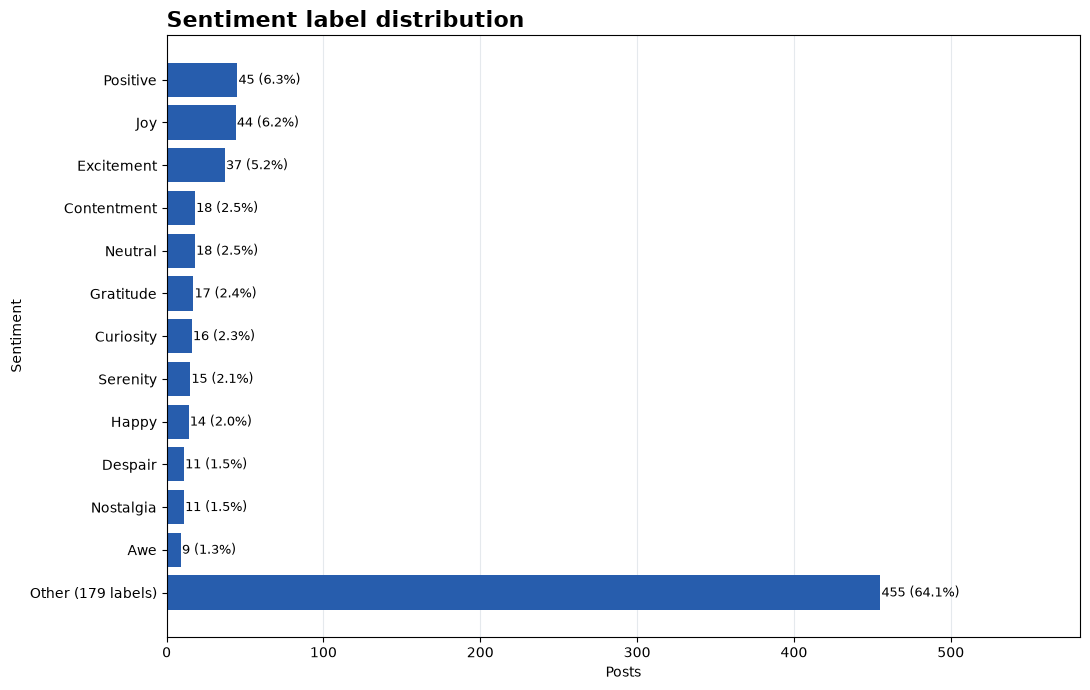

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from pathlib import Path
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data/processed/sentiment_cleaned.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Run inside the extracted repository with data/processed/sentiment_cleaned.csv present.')
INPUT=ROOT/'data/processed/sentiment_cleaned.csv'
BASE=ROOT
EDA_DIR=ROOT/'generated/eda_sentiment'
EDA_DIR.mkdir(parents=True,exist_ok=True)
df = pd.read_csv(INPUT)
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='raise')

# Count all labels, then group the long tail for a readable chart.
counts = df['sentiment'].value_counts().sort_values(ascending=False)
top_labels = counts.head(12)
chart_counts = top_labels.copy()
other_count = int(counts.iloc[12:].sum())
if other_count:
    chart_counts.loc[f'Other ({len(counts) - len(top_labels)} labels)'] = other_count
shares = chart_counts / len(df) * 100

fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(chart_counts.index[::-1], chart_counts.values[::-1], color='#275DAD')
ax.set_xlim(0, max(chart_counts.values) * 1.28)
ax.set_title('Sentiment label distribution', loc='left', fontsize=16, weight='bold')
ax.set_xlabel('Posts')
ax.set_ylabel('Sentiment')
ax.grid(axis='x', color='#E5E9ED', linewidth=0.8)
ax.set_axisbelow(True)
for bar, label in zip(bars, chart_counts.index[::-1]):
    value = int(chart_counts[label])
    ax.text(value + 0.8, bar.get_y() + bar.get_height()/2, f'{value} ({shares[label]:.1f}%)', va='center', fontsize=9)
fig.tight_layout()
chart_path = EDA_DIR / '01_sentiment_distribution.svg'
fig.savefig(chart_path, format='svg', bbox_inches='tight')
print(f'Saved {chart_path}; {len(df)} posts and {len(counts)} sentiment labels.')
display(fig)
plt.close(fig)


### 7.2 Sentiment and interactions
Boxplots compare total interactions for frequent labels with at least 8 observations. Sample sizes are shown.

Saved ./generated/eda_sentiment/02_sentiment_interactions.svg; showing 12 labels with at least 8 posts.


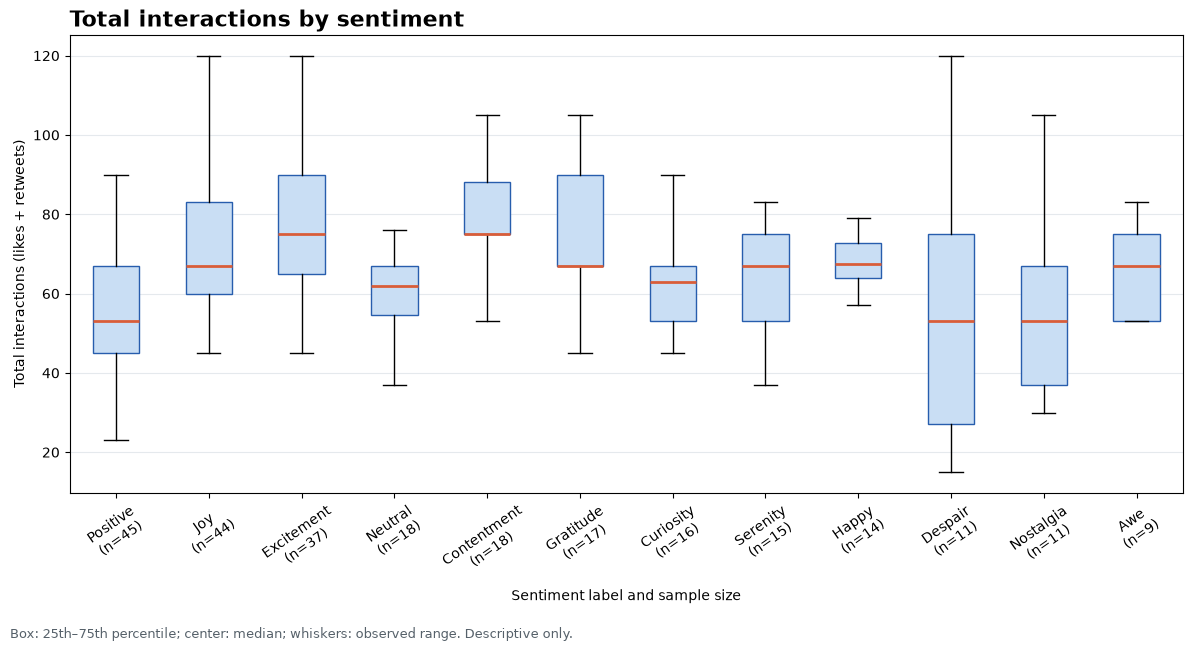

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from pathlib import Path
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data/processed/sentiment_cleaned.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Run inside the extracted repository with data/processed/sentiment_cleaned.csv present.')
INPUT=ROOT/'data/processed/sentiment_cleaned.csv'
BASE=ROOT
EDA_DIR=ROOT/'generated/eda_sentiment'
EDA_DIR.mkdir(parents=True,exist_ok=True)
df = pd.read_csv(INPUT)
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='raise')

# Compare interaction distributions for the 12 most frequent labels with n >= 8.
counts = df['sentiment'].value_counts()
selected = counts[counts >= 8].head(12).index.tolist()
box_data = [df.loc[df['sentiment'].eq(label), 'total_interactions'].astype(float).to_numpy() for label in selected]
labels = [f'{label}\n(n={int(counts[label])})' for label in selected]

fig, ax = plt.subplots(figsize=(12, 6.5))
box = ax.boxplot(box_data, tick_labels=labels, patch_artist=True, whis=(0, 100), showfliers=True, medianprops={'color':'#D95D39','linewidth':2})
for patch in box['boxes']:
    patch.set_facecolor('#C9DEF4')
    patch.set_edgecolor('#275DAD')
ax.set_title('Total interactions by sentiment', loc='left', fontsize=16, weight='bold')
ax.set_ylabel('Total interactions (likes + retweets)')
ax.set_xlabel('Sentiment label and sample size')
ax.grid(axis='y', color='#E5E9ED', linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(axis='x', labelrotation=35)
fig.text(0.01, 0.01, 'Box: 25th–75th percentile; center: median; whiskers: observed range. Descriptive only.', fontsize=9, color='#56616A')
fig.tight_layout(rect=(0, 0.04, 1, 1))
chart_path = EDA_DIR / '02_sentiment_interactions.svg'
fig.savefig(chart_path, format='svg', bbox_inches='tight')
print(f'Saved {chart_path}; showing {len(selected)} labels with at least 8 posts.')
display(fig)
plt.close(fig)


### 7.3 Sentiment over time
Annual counts for the five most frequent labels, with total posts per year to show uneven coverage.

Saved ./generated/eda_sentiment/03_sentiment_over_time.svg; coverage from 2010 to 2023.


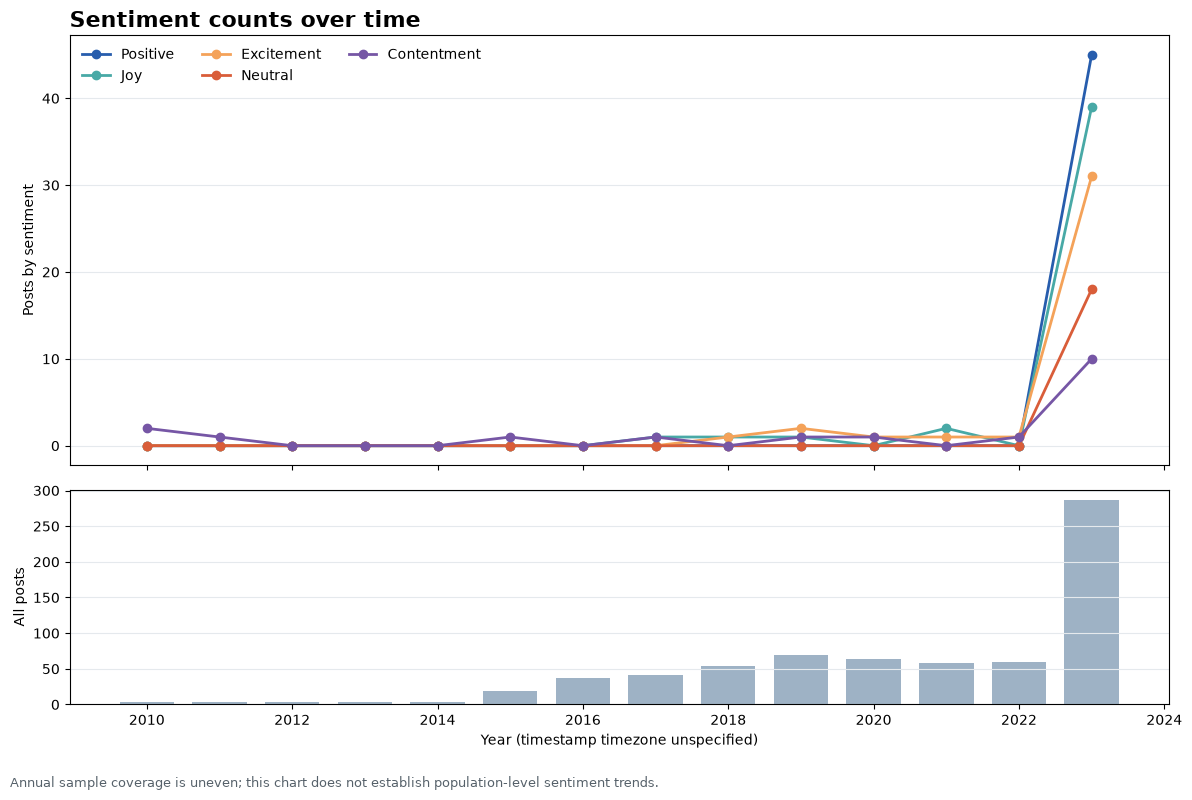

In [3]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from pathlib import Path
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data/processed/sentiment_cleaned.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Run inside the extracted repository with data/processed/sentiment_cleaned.csv present.')
INPUT=ROOT/'data/processed/sentiment_cleaned.csv'
BASE=ROOT
EDA_DIR=ROOT/'generated/eda_sentiment'
EDA_DIR.mkdir(parents=True,exist_ok=True)
df = pd.read_csv(INPUT)
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='raise')

# Plot annual counts for the five most frequent labels and total yearly coverage.
year_counts = df['sentiment'].value_counts()
top_labels = year_counts.head(5).index.tolist()
annual_sentiment = df.assign(year=df['timestamp'].dt.year).groupby(['year', 'sentiment']).size().unstack(fill_value=0)
annual_total = df.groupby(df['timestamp'].dt.year).size()

fig, (ax, ax_total) = plt.subplots(2, 1, figsize=(12, 8), sharex=True, gridspec_kw={'height_ratios':[2, 1]})
colors = ['#275DAD', '#48A9A6', '#F4A259', '#D95D39', '#7656A5']
for label, color in zip(top_labels, colors):
    values = annual_sentiment[label] if label in annual_sentiment else 0
    ax.plot(annual_sentiment.index, values, marker='o', linewidth=2, label=label, color=color)
ax.set_title('Sentiment counts over time', loc='left', fontsize=16, weight='bold')
ax.set_ylabel('Posts by sentiment')
ax.legend(ncol=3, frameon=False)
ax.grid(axis='y', color='#E5E9ED', linewidth=0.8)
ax_total.bar(annual_total.index, annual_total.values, color='#9EB2C5', width=0.75)
ax_total.set_ylabel('All posts')
ax_total.set_xlabel('Year (timestamp timezone unspecified)')
ax_total.grid(axis='y', color='#E5E9ED', linewidth=0.8)
fig.text(0.01, 0.01, 'Annual sample coverage is uneven; this chart does not establish population-level sentiment trends.', fontsize=9, color='#56616A')
fig.tight_layout(rect=(0, 0.04, 1, 1))
chart_path = EDA_DIR / '03_sentiment_over_time.svg'
fig.savefig(chart_path, format='svg', bbox_inches='tight')
print(f'Saved {chart_path}; coverage from {annual_total.index.min()} to {annual_total.index.max()}.')
display(fig)
plt.close(fig)
